## eThekwini 2026 Local Government Election Forecast

## Part A pipeline Code

## 1. Configuration 

In [3]:
import itertools
from pathlib import Path

import joblib
from joblib import Parallel, delayed

import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold

In [4]:
MODEL_PATH = Path.cwd() / "models" / "ethekwini_models.joblib"

SHORT = {"AFRICAN NATIONAL CONGRESS": "ANC", "DEMOCRATIC ALLIANCE": "DA",
         "ECONOMIC FREEDOM FIGHTERS": "EFF", "INKATHA FREEDOM PARTY": "IFP",
         "ACTIONSA": "ActionSA"}
CORE = ["ANC", "DA", "EFF", "IFP", "OTHER"]            # block that has history in 2016 AND 2021
FULL = ["ANC", "DA", "EFF", "IFP", "ActionSA", "OTHER"]  # ActionSA first contested in 2021
RELEVANT = ["ANC", "DA", "EFF", "IFP", "ActionSA"]      # >=2% of 2021 PR vote
EPS = 0.002                                             # smoothing for log of zero shares

DEFAULTS = dict(
    persistence=0.5,        # share of the 2016->2021 swing assumed to continue (0 = freeze at 2021)
    turnout_reversion=0.5,  # share of the 2016->2021 turnout fall that reverses (0 = stay at 2021)
    reg_growth=0.0,         # change in registered voters vs 2021 (enter IEC figure when published)
    actionsa_mult=1.0,      # ActionSA strength vs its 2021 share of the "other" block
    emerging_share=0.0,     # scenario: share taken by a party with NO history in the data (e.g. MK)
    n_sims=1000, seed=42,
    sd_persist=0.25, sd_party=0.15, sd_turnout=0.04)       # Monte-Carlo uncertainty
SELECTED_WARDS = None   # e.g. [59500010, 59500045, 59500090]; None = auto-pick 3 contrasting wards

## 2. Data Collection 

In [5]:
def find_datasets(data_dir='Users\22354752'):
    """Locate the 3 CSVs by CONTENT (not file name) so renamed files like 'ETH (1).csv' still work.
    Searches: data_dir, the working folder, ./data, the parent folder and their immediate sub-folders."""
    here = Path.cwd()
    dirs = ([Path(data_dir)] if data_dir else []) + [here, here / "data", here.parent]
    for base in (here, here.parent):
        try:
            dirs += [d for d in base.iterdir() if d.is_dir() and not d.name.startswith((".", "$"))]
        except OSError:
            pass
    found = {}
    for d in dirs:
        try:
            files = sorted(d.glob("*.csv"))
        except OSError:
            continue
        for f in files:
            try:
                h = pd.read_csv(f, nrows=2)
            except Exception:
                continue
            if {"BallotType", "DateGenerated"} <= set(h.columns):          # election-results file
                found.setdefault({2016: "y2016", 2021: "y2021"}.get(pd.to_datetime(h.DateGenerated.iloc[0]).year, "other"), f)
            elif {"VDNumber", "WardId"} <= set(h.columns):                 # 2026 voting-district file
                found.setdefault("geo", f)
    missing = [k for k in ("y2016", "y2021", "geo") if k not in found]
    if missing:
        raise FileNotFoundError(f"Could not find dataset(s) {missing}. Working folder is {here}. "
                                f"Put the 3 CSVs in that folder (or a 'data' sub-folder), or run os.chdir(<folder>) first.")
    return found


def load_data(data_dir=None):
    found = find_datasets(data_dir)
    for k, f in found.items():
        print(f"  {k:>5}: {f}")
    r16, r21 = pd.read_csv(found["y2016"]), pd.read_csv(found["y2021"])
    geo = pd.read_csv(found["geo"]).rename(
        columns={"Municipali": "Municipality", "WardId": "Ward26", "VDNumber": "VD"})
    geo["Rural"] = (geo.sType == "Rural").astype(int)
    geo["AreaLog"] = np.log(geo.Shape__Area)
    return r16, r21, geo

## 3. Data Cleaning and Audit

In [6]:
def vd_table(raw, ballot, merge_actionsa):
    """Long file (VD x party rows) -> one row per VD with votes per party block."""
    d = raw[raw.BallotType == ballot].copy()
    d["Ward"] = d.Ward.str.extract(r"(\d+)")[0].astype(int)
    d["P"] = d.PartyName.str.strip().str.upper().map(SHORT).fillna("OTHER")
    if merge_actionsa:                       # 2016 has no ActionSA -> keep blocks comparable
        d.loc[d.P == "ActionSA", "P"] = "OTHER"
    votes = d.pivot_table(index="VotingDistrict", columns="P", values="TotalValidVotes",
                          aggfunc="sum", fill_value=0)
    cols = [c for c in FULL if not (merge_actionsa and c == "ActionSA")]
    votes = votes.reindex(columns=cols, fill_value=0)
    meta = d.groupby("VotingDistrict").agg(Ward=("Ward", "first"), Registered=("RegisteredVoters", "first"),
                                           Spoilt=("SpoiltVotes", "first"))
    t = meta.join(votes)
    t["Valid"] = votes.sum(axis=1)
    t["Cast"] = t.Valid + t.Spoilt
    t = t[(t.Registered > 0) & (t.Valid > 0)]            # drop unusable VDs
    t["Turnout"] = (t.Cast / t.Registered).clip(0.02, 0.98)
    return t


def data_audit(r16, r21, geo):
    """Evidence for which datasets are usable (shown on the dashboard)."""
    rows = []
    for name, r in [("2016 results (ETH__1_.csv)", r16), ("2021 results (ETH.csv)", r21)]:
        pr = r[r.BallotType == "PR"].drop_duplicates("VotingDistrict")
        rows.append(dict(Dataset=name, Rows=len(r), Wards=r.Ward.nunique(), VDs=r.VotingDistrict.nunique(),
                         Parties=r.PartyName.nunique(), Missing=int(r.isna().sum().sum()),
                         Registered=int(pr.RegisteredVoters.sum()),
                         Turnout=round((r[r.BallotType == "PR"].groupby("PartyName").TotalValidVotes.sum().sum()
                                        + pr.SpoiltVotes.sum()) / pr.RegisteredVoters.sum() * 100, 1)))
    rows.append(dict(Dataset="2026 districts (Pre_Election_Voting_Districts_2026.csv)", Rows=len(geo),
                     Wards=geo.Ward26.nunique(), VDs=geo.VD.nunique(), Parties=0,
                     Missing=int(geo.isna().sum().sum()), Registered=0, Turnout=np.nan))
    return pd.DataFrame(rows)

## 4. Feature Engineering 

In [7]:
def clr(sh):
    z = np.log(np.asarray(sh, dtype=float) + EPS)
    return z - z.mean(-1, keepdims=True)


def softmax(z):
    e = np.exp(z - z.max(-1, keepdims=True))
    return e / e.sum(-1, keepdims=True)


logit = lambda p: np.log(p / (1 - p))
expit = lambda x: 1 / (1 + np.exp(-x))


def feat_from(sh, turnout, reg, ward, rural, arealog):
    """Model inputs describing a VD at time t (used to predict change to t+1)."""
    X = pd.DataFrame({"sh_" + p: sh[p] for p in CORE})                    # own party strength
    X["turnout"], X["logreg"] = turnout, np.log(reg)                       # engagement, size
    w = sh.mul(reg, axis=0).groupby(ward).transform("sum")                 # ward context
    w = w.div(w.sum(axis=1), axis=0)
    for p in CORE:
        X["wsh_" + p] = w[p]
    X["Rural"], X["density"] = rural, X["logreg"] - arealog                # geography (2026 file)
    return X


def shares_core(t):
    return t[CORE].div(t.Valid, axis=0)

## 5. Model Training and Evaluation 

In [9]:
def _model():
    return HistGradientBoostingRegressor(max_depth=3, max_iter=150, learning_rate=0.05,
                                         min_samples_leaf=20, l2_regularization=1.0, random_state=0)


def fit(X, R, w):
    return {c: _model().fit(X, R[c], sample_weight=w) for c in R.columns}


def predict(models, X):
    return pd.DataFrame({c: m.predict(X) for c, m in models.items()}, index=X.index)


def train(ballot, r16, r21, geo, run_cv=True):
    """Learn 2016->2021 behaviour at VD level for one ballot type ('PR' or 'Ward')."""
    t16, t21m, t21 = vd_table(r16, ballot, True), vd_table(r21, ballot, True), vd_table(r21, ballot, False)
    g = geo.set_index("VD")
    idx = t16.index.intersection(t21m.index)

    def X_of(t):
        return feat_from(shares_core(t), t.Turnout, t.Registered, t.Ward,
                         g.Rural.reindex(t.index), g.AreaLog.reindex(t.index))
    X16 = X_of(t16).loc[idx]
    Z16 = pd.DataFrame(clr(shares_core(t16)), index=t16.index, columns=CORE).loc[idx]
    Z21 = pd.DataFrame(clr(shares_core(t21m)), index=t21m.index, columns=CORE).loc[idx]
    Y = Z21 - Z16                                                           # change in CLR space
    Y["TURN"] = logit(t21m.Turnout.loc[idx]) - logit(t16.Turnout.loc[idx])  # change in turnout logit
    w = t16.Valid.loc[idx]
    dbar = pd.Series(np.average(Y, axis=0, weights=w), index=Y.columns)    # metro-wide swing
    models = fit(X16, Y - dbar, w)                                          # local deviations only
    b = dict(ballot=ballot, models=models, dbar=dbar, t16=t16, t21=t21, t21m=t21m,
             spoilt_rate=float((t21.Spoilt.sum()) / t21.Cast.sum()), n_train=len(idx))
    b["cv"] = backtest(X16, Y, w, Z16, t16.loc[idx], t21m.loc[idx]) if run_cv else None
    return b


def backtest(X, Y, w, Z16, t16, t21m):
    """Grouped 5-fold CV (folds = wards, so a ward never sits in train AND test).
    Compares the ML model with two naive baselines on the 2016->2021 transition."""
    oof = {k: Z16.copy() for k in ["none", "swing", "model"]}
    oof_t = {k: pd.Series(0.0, index=X.index) for k in ["none", "swing", "model"]}
    T16 = logit(t16.Turnout)
    def one_fold(tr, te):                                   # joblib: the 5 folds train in parallel
        db = pd.Series(np.average(Y.iloc[tr], axis=0, weights=w.iloc[tr]), index=Y.columns)
        return te, db, predict(fit(X.iloc[tr], Y.iloc[tr] - db, w.iloc[tr]), X.iloc[te])
    folds = Parallel(n_jobs=-1)(delayed(one_fold)(tr, te) for tr, te in GroupKFold(5).split(X, groups=t16.Ward))
    for te, db, pr in folds:
        ix = X.index[te]
        oof["swing"].loc[ix] = Z16.loc[ix].values + db[CORE].values
        oof["model"].loc[ix] = Z16.loc[ix].values + db[CORE].values + pr[CORE].values
        oof_t["none"].loc[ix] = t16.Turnout.loc[ix]
        oof_t["swing"].loc[ix] = expit(T16.loc[ix] + db["TURN"])
        oof_t["model"].loc[ix] = expit(T16.loc[ix] + db["TURN"] + pr["TURN"])
    actual = shares_core(t21m)[CORE[:4]]
    rows = []
    for k, lab in [("none", "Baseline A: no change"), ("swing", "Baseline B: uniform swing"),
                   ("model", "ML: swing + GBM local residual")]:
        sh = pd.DataFrame(softmax(oof[k].values), index=X.index, columns=CORE)
        mae = (sh[CORE[:4]] - actual).abs().mean().mean() * 100
        # ward winners among the 4 big parties, using actual 2021 vote volumes
        pv = sh[CORE[:4]].mul(t21m.Valid, axis=0).groupby(t21m.Ward).sum()
        av = t21m[CORE[:4]].groupby(t21m.Ward).sum()
        acc = (pv.idxmax(axis=1) == av.idxmax(axis=1)).mean() * 100
        metro = (sh.mul(t21m.Valid, axis=0).sum() / t21m.Valid.sum())[CORE[:4]]
        metro_err = (metro - t21m[CORE[:4]].sum() / t21m.Valid.sum()).abs().mean() * 100
        rows.append({"Model": lab, "VD share MAE (pp)": round(mae, 2),
                     "Ward-winner accuracy (%)": round(acc, 1),
                     "Metro share error (pp)": round(metro_err, 2),
                     "VD turnout MAE (pp)": round((oof_t[k] - t21m.Turnout).abs().mean() * 100, 2)})
    return pd.DataFrame(rows)

## 6. 2026 Prediction

In [10]:
def build_frame(b, geo, p):
    """2026 prediction frame = the 838 districts in the 2026 file, carrying 2021 history."""
    f = geo.set_index("VD")[["Ward26", "Rural", "AreaLog"]].copy()
    sh21 = shares_core(b["t21m"])
    asa = b["t21"]["ActionSA"] / b["t21m"]["OTHER"]                          # ActionSA share of OTHER block
    base = sh21.join(asa.rename("r")).join(b["t21m"][["Turnout", "Registered"]]).reindex(f.index)
    base = base.fillna(base.groupby(f.Ward26).transform("mean"))             # brand-new VDs: ward mean
    base = base.fillna(base.mean())                                          # ... else metro mean
    reg = base.Registered * (b["t21m"].Registered.sum() * (1 + p["reg_growth"]) / base.Registered.sum())
    X = feat_from(base[CORE], base.Turnout, reg, f.Ward26, f.Rural, f.AreaLog)
    resid = predict(b["models"], X)
    # centre the local residuals: the GBM may only REDISTRIBUTE swing between districts; the metro-wide
    # level is controlled by dbar x persistence (otherwise 2016-calibrated levels leak into the metro total)
    resid = resid - np.average(resid, axis=0, weights=reg.values)
    Zb = clr(base[CORE]) + resid[CORE].values                                # local part of the forecast
    d_turn = b["dbar"]["TURN"] + resid["TURN"].values                        # full predicted 2016->21 style change
    Tz = logit(base.Turnout.clip(0.02, 0.98)) - p["turnout_reversion"] * d_turn
    return dict(f=f, Zb=Zb, T0=expit(Tz.values), reg=reg.values, r=base.r.clip(0, 1).values)


def expand(core, r, p):
    """5 modelled blocks -> reporting parties (split ActionSA out of OTHER, add scenario party)."""
    oth = core[..., 4]
    asa = np.minimum(oth * r * p["actionsa_mult"], oth * 0.95)
    out = np.concatenate([core[..., :4], asa[..., None], (oth - asa)[..., None]], -1) * (1 - p["emerging_share"])
    if p["emerging_share"] > 0:
        out = np.concatenate([out, np.full(out[..., :1].shape, p["emerging_share"])], -1)
    return out


def seats_lr(shares, total):
    """Largest-remainder seat allocation (vectorised)."""
    q = shares * total
    s = np.floor(q).astype(int)
    rem = total - s.sum(-1)
    rank = np.argsort(np.argsort(-(q - s), axis=-1), axis=-1)
    return s + (rank < rem[..., None])


def forecast(b, geo, p):
    fr = build_frame(b, geo, p)
    names = FULL + (["Emerging"] if p["emerging_share"] > 0 else [])
    rng = np.random.default_rng(p["seed"])
    S, N = int(p["n_sims"]), len(fr["f"])
    wards = pd.get_dummies(fr["f"].Ward26).astype(float)                    # ward membership matrix
    dbar = b["dbar"][CORE].values
    persist = np.r_[p["persistence"], rng.normal(p["persistence"], p["sd_persist"], S)]   # row 0 = point est.
    noise = np.vstack([np.zeros(5), rng.normal(0, p["sd_party"], (S, 5))])
    tshift = np.r_[0, rng.normal(0, p["sd_turnout"], S)]
    Z = fr["Zb"][None] + persist[:, None, None] * dbar + noise[:, None, :]  # (S+1, N, 5)
    sh = expand(softmax(Z), fr["r"], p)                                      # (S+1, N, K)
    T = np.clip(fr["T0"][None] + tshift[:, None], 0.15, 0.95)               # (S+1, N)
    cast = fr["reg"][None] * T
    valid = cast * (1 - b["spoilt_rate"])
    votes = sh * valid[..., None]
    ward_votes = np.einsum("nw,snk->swk", wards.values, votes)
    out = dict(names=names, wards=wards.columns.values, fr=fr,
               metro_votes=votes.sum(1), cast=cast.sum(1), valid=valid.sum(1), reg=fr["reg"].sum(),
               ward_votes=ward_votes)
    out["metro_share"] = out["metro_votes"] / out["metro_votes"].sum(-1, keepdims=True)
    vd = pd.DataFrame(sh[0], index=fr["f"].index, columns=names)
    vd["Ward26"], vd["Registered"], vd["Turnout"] = fr["f"].Ward26, fr["reg"], T[0]
    vd["Votes"] = valid[0]
    out["vd"] = vd
    return out

## 7. Interpretation: seats, coalitions, ward leaders, headline outputs

In [11]:
def coalitions(seats, names, majority, top=8):
    """All MINIMAL winning coalitions (no member can leave without losing the majority)."""
    named = [(n, s) for n, s in zip(names, seats) if n != "OTHER" and s > 0]
    res = []
    for k in range(1, len(named) + 1):
        for combo in itertools.combinations(named, k):
            tot = sum(s for _, s in combo)
            if tot >= majority and all(tot - s < majority for _, s in combo):
                res.append((" + ".join(n for n, _ in combo), tot, tot - majority))
    res.sort(key=lambda x: (x[0].count("+"), x[2]))
    return pd.DataFrame(res[:top], columns=["Coalition", "Seats", "Surplus over majority"])


def auto_select_wards(wt):
    """3 contrasting wards: strongest DA ward, strongest rural ANC ward, tightest race."""
    picks = []
    da = wt[wt.Leader == "DA"].sort_values("Margin", ascending=False)
    anc = wt[(wt.Leader == "ANC") & (wt.Rural > .5)].sort_values("Lead share", ascending=False)
    close = wt.sort_values("Margin")
    for cand in [da, anc, close, wt]:
        for w in cand.index:
            if w not in picks:
                picks.append(w); break
    return picks[:3]


def run_all(bundles, geo, p=None, wards=SELECTED_WARDS):
    p = {**DEFAULTS, **(p or {})}
    pr, wd = forecast(bundles["PR"], geo, p), forecast(bundles["Ward"], geo, p)
    names, K = pr["names"], len(pr["names"])
    n_seats = 2 * geo.Ward26.nunique()                    # 112 ward + 112 PR-compensatory seats
    majority = n_seats // 2 + 1
    seats = seats_lr(pr["metro_share"], n_seats)          # (S+1, K)
    big = [i for i, n in enumerate(names) if n != "OTHER"]
    # --- Output 1: largest party + coalition outlook
    lead = seats[1:][:, big].argmax(1)
    o1 = dict(seats=pd.Series(seats[0], index=names), n_seats=n_seats, majority=majority,
              largest=names[big[int(np.argmax(seats[0][big]))]],
              p_largest=pd.Series([(lead == j).mean() for j in range(len(big))], index=[names[i] for i in big]),
              p_hung=float((seats[1:].max(1) < majority).mean()),
              coalitions=coalitions(seats[0], names, majority))
    o1["single_majority"] = seats[0].max() >= majority
    # --- Output 3: vote share (point + 80% interval)
    ms = pr["metro_share"]
    o3 = pd.DataFrame({"Projected share (%)": ms[0] * 100, "Low (10th pct)": np.percentile(ms[1:], 10, 0) * 100,
                       "High (90th pct)": np.percentile(ms[1:], 90, 0) * 100, "Projected votes": pr["metro_votes"][0],
                       "Seats": seats[0]}, index=names).round(1)
    # --- Output 4: turnout
    o4 = dict(registered=pr["reg"], turnout=pr["cast"][0] / pr["reg"], ballots=pr["cast"][0],
              lo=np.percentile(pr["cast"][1:], 10), hi=np.percentile(pr["cast"][1:], 90))
    # --- Output 2: ward leaders (Ward ballot, relevant parties only; independents sit in OTHER)
    rel = [i for i, n in enumerate(wd["names"]) if n in RELEVANT + ["Emerging"]]
    wv = wd["ward_votes"]
    order = np.argsort(-wv[0][:, rel], axis=1)
    rows = np.arange(wv.shape[1])
    top1, top2 = np.array(rel)[order[:, 0]], np.array(rel)[order[:, 1]]
    tot = wv[0].sum(1)
    wt = pd.DataFrame({"Leader": [wd["names"][i] for i in top1], "Runner-up": [wd["names"][i] for i in top2],
                       "Lead share": wv[0][rows, top1] / tot * 100,
                       "Margin": (wv[0][rows, top1] - wv[0][rows, top2]) / tot * 100,
                       "Rural": wd["vd"].groupby("Ward26").apply(lambda d: geo.set_index("VD").Rural.reindex(d.index).mean()).values},
                      index=wd["wards"])
    wins = (wv[1:][:, :, rel].argmax(2)[:, :, None] == np.arange(len(rel))).mean(0)  # P(win) per ward x party
    leader_prob = wins[rows, [rel.index(i) for i in top1]]
    wt["P(leader wins)"] = leader_prob * 100
    wt = wt.round(1)
    chosen = wards or auto_select_wards(wt)
    return dict(params=p, o1=o1, o2=wt.loc[chosen], ward_all=wt, o3=o3, o4=o4, pr=pr, wd=wd,
                chosen=chosen, shares_by_ward=pd.DataFrame(wv[0][:, :] / tot[:, None] * 100, index=wd["wards"],
                                                           columns=wd["names"]).round(1))


def history(bundles):
    """Actual 2016/2021 PR results for context charts."""
    h = {}
    for yr, k in [("2016", "t16"), ("2021", "t21")]:
        t = bundles["PR"][k]
        h[yr] = dict(share=(t[[c for c in FULL if c in t]].sum() / t.Valid.sum() * 100).round(1),
                     turnout=t.Cast.sum() / t.Registered.sum(), registered=int(t.Registered.sum()),
                     ballots=int(t.Cast.sum()))
    return h


def train_all(data_dir=None, run_cv=True, use_saved=True, save=True):
    """Train both ballot models, or reload them with joblib (stage: model persistence)."""
    r16, r21, geo = load_data(data_dir)
    audit = data_audit(r16, r21, geo)
    if use_saved and MODEL_PATH.exists():
        print(f"Loading saved models from {MODEL_PATH}")
        return joblib.load(MODEL_PATH), geo, audit
    bundles = {"PR": train("PR", r16, r21, geo, run_cv), "Ward": train("Ward", r16, r21, geo, run_cv)}
    if save:
        MODEL_PATH.parent.mkdir(exist_ok=True)
        joblib.dump(bundles, MODEL_PATH, compress=3)
        print(f"Models saved to {MODEL_PATH}")
    return bundles, geo, audit

## Part B: ML Lifecycle

## 1. Problem Definition and target

Four outputs for the 04 Nov 2026 eThekwini election: (1) largest party + coalitions, (2) leader in 3 wards, (3) vote share per relevant party, (4) projected number of voters.

In [12]:
import warnings; warnings.filterwarnings("ignore")
from IPython.display import display
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
COL = {"ANC":"#2e7d32","DA":"#1565c0","EFF":"#c62828","IFP":"#e65100","ActionSA":"#00838f","OTHER":"#9e9e9e","Emerging":"#6a1b9a"}
print("Setup complete. Notebook working folder:", Path.cwd())

Setup complete. Notebook working folder: C:\Users\22354752


## 2. Data collection and audits 

In [17]:
r16, r21, geo = load_data()
audit = data_audit(r16, r21, geo)
display(audit)
print("2026 file has NO vote columns -> used only as the prediction frame (districts, wards, urban/rural).")
print("Ballot types:", r21.BallotType.unique(), "| 2021 sample:"); display(r21.head(3))

  y2016: C:\Users\22354752\2016_Results.csv
  y2021: C:\Users\22354752\ETH.csv
    geo: C:\Users\22354752\Pre_Election_Voting_Districts_2026.csv


,Dataset,Rows,Wards,VDs,Parties,Missing,Registered,Turnout
0,2016 results (ETH__1_.csv),40706,110,866,28,0,1919724,59.1
1,2021 results (ETH.csv),76740,111,875,54,0,1909125,41.5
2,2026 districts (Pre_Election_Voting_Districts_...,838,112,838,0,0,0,NaN


2026 file has NO vote columns -> used only as the prediction frame (districts, wards, urban/rural).
Ballot types: <ArrowStringArray>
['PR', 'Ward']
Length: 2, dtype: str | 2021 sample:


,Province,Municipality,Ward,VotingDistrict,VotingStationName,RegisteredVoters,BallotType,SpoiltVotes,PartyName,TotalValidVotes,DateGenerated
0,KwaZulu-Natal,ETH - eThekwini,Ward 59500001,43400179,NOMFIHLELA PRIMARY SCHOOL,2365,PR,12,ABANTU BATHO CONGRESS,14,11/23/2021 4:26:30 PM
1,KwaZulu-Natal,ETH - eThekwini,Ward 59500001,43400179,NOMFIHLELA PRIMARY SCHOOL,2365,PR,12,ACADEMIC CONGRESS UNION,0,11/23/2021 4:26:30 PM
2,KwaZulu-Natal,ETH - eThekwini,Ward 59500001,43400179,NOMFIHLELA PRIMARY SCHOOL,2365,PR,12,ACTIONSA,0,11/23/2021 4:26:30 PM


## 4. Exploratory Data analysis

,2016,2021
ANC,59.1,42.5
DA,27.5,26.3
EFF,3.6,10.8
IFP,4.3,7.5
ActionSA,0.0,2.3
OTHER,5.4,10.6


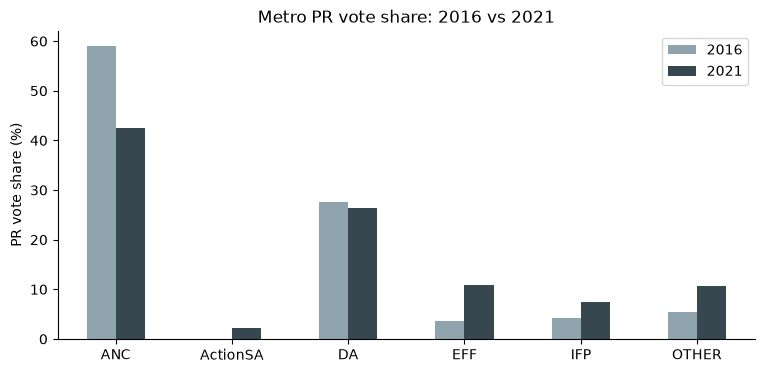

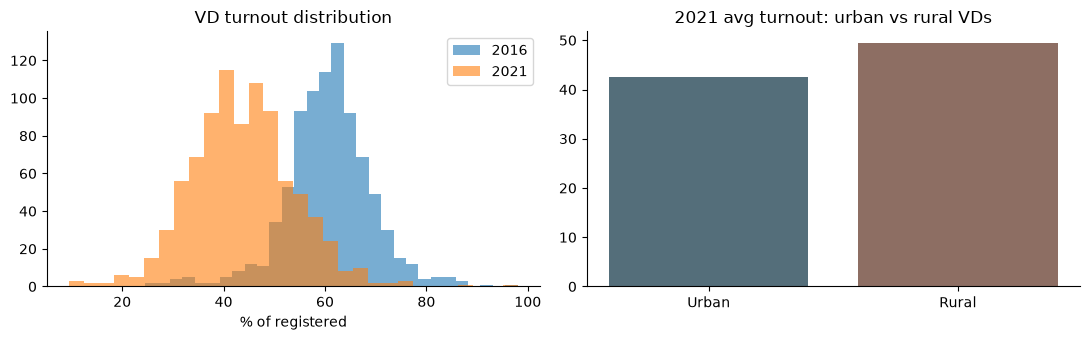

In [18]:
pr16, pr21 = vd_table(r16, "PR", False), vd_table(r21, "PR", False)
sh = pd.DataFrame({"2016": pr16[["ANC","DA","EFF","IFP","OTHER"]].sum()/pr16.Valid.sum()*100,
                   "2021": pr21[FULL].sum()/pr21.Valid.sum()*100}).fillna(0).round(1)
display(sh.reindex(["ANC","DA","EFF","IFP","ActionSA","OTHER"]))
ax = sh.plot.bar(color=["#90a4ae","#37474f"]); ax.set_ylabel("PR vote share (%)"); ax.set_title("Metro PR vote share: 2016 vs 2021")
plt.xticks(rotation=0); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for y, t in [("2016", pr16), ("2021", pr21)]: ax[0].hist(t.Turnout*100, bins=30, alpha=.6, label=y)
ax[0].set_title("VD turnout distribution"); ax[0].set_xlabel("% of registered"); ax[0].legend()
rural = geo.set_index("VD").Rural.reindex(pr21.index)
ax[1].bar(["Urban","Rural"], [pr21[rural==0].Turnout.mean()*100, pr21[rural==1].Turnout.mean()*100], color=["#546e7a","#8d6e63"])
ax[1].set_title("2021 avg turnout: urban vs rural VDs"); plt.tight_layout(); plt.show()

## 5. Feature engineering, training, validation

  y2016: C:\Users\22354752\2016_Results.csv
  y2021: C:\Users\22354752\ETH.csv
    geo: C:\Users\22354752\Pre_Election_Voting_Districts_2026.csv
Models saved to C:\Users\22354752\models\ethekwini_models.joblib


,Model,VD share MAE (pp),Ward-winner accuracy (%),Metro share error (pp),VD turnout MAE (pp)
0,Baseline A: no change,7.96,96.4,7.04,17.65
1,Baseline B: uniform swing,5.04,97.3,1.28,6.12
2,ML: swing + GBM local residual,4.09,98.2,0.16,4.71


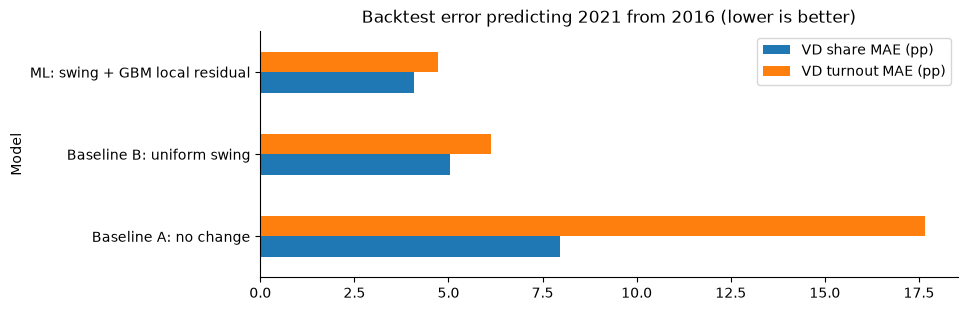

In [19]:
bundles, geo, audit = train_all(use_saved=False)      # trains + saves with joblib (cross-validation runs in parallel)
cv = bundles["PR"]["cv"]; display(cv)
ax = cv.set_index("Model")[["VD share MAE (pp)","VD turnout MAE (pp)"]].plot.barh(figsize=(9,3.2))
ax.set_title("Backtest error predicting 2021 from 2016 (lower is better)"); plt.show()

In [20]:
# Demonstrate joblib: reload the saved model file exactly as a deployed app would
reloaded = joblib.load(MODEL_PATH)
print("Saved file:", MODEL_PATH, "-", round(MODEL_PATH.stat().st_size/1e6, 2), "MB | keys:", list(reloaded))

Saved file: C:\Users\22354752\models\ethekwini_models.joblib - 0.8 MB | keys: ['PR', 'Ward']


In [21]:
# Which inputs does the local model use? (permutation-free view: the learned swing per party)
print("Metro-wide 2016->2021 swing in CLR space (positive = gained):"); display(bundles["PR"]["dbar"].round(3).to_frame("swing"))

Metro-wide 2016->2021 swing in CLR space (positive = gained):


,swing
ANC,-0.775
DA,-0.741
EFF,0.544
IFP,0.471
OTHER,0.502
TURN,-0.761


## 6. Prediction

In [24]:
params = dict(persistence=0.5, turnout_reversion=0.5, reg_growth=0.0, actionsa_mult=1.0, emerging_share=0.0, n_sims=1000)
SELECTED_WARDS = None      # e.g. [59500010, 59500045, 59500090]; None = auto-pick 3 contrasting wards
R = run_all(bundles, geo, params, wards=SELECTED_WARDS)
print("Forecast complete.")

Forecast complete.


## Output 1: Largest party and coalitions

Largest party: ANC | single-party majority: False | majority needed: 113 of 224 seats | P(hung council) = 99%


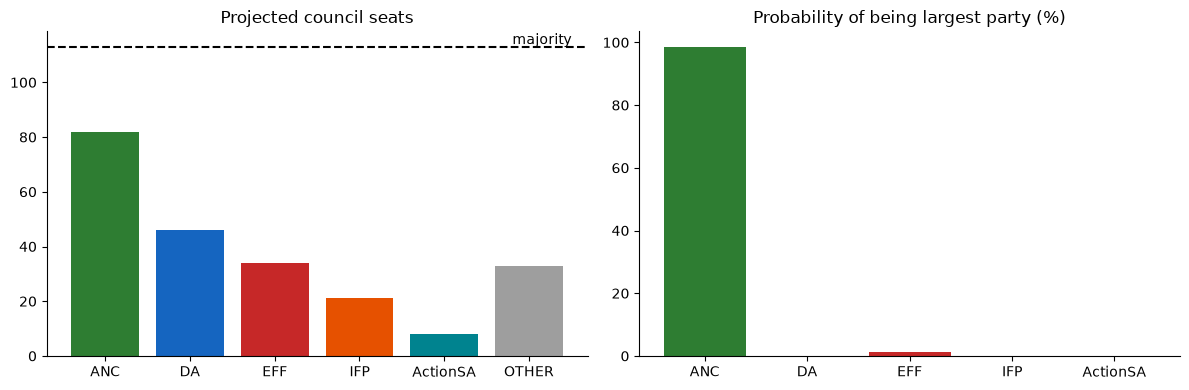

Minimal winning coalitions (arithmetic only - the data say nothing about who will co-operate):


,Coalition,Seats,Surplus over majority
0,ANC + EFF,116,3
1,ANC + DA,128,15


In [25]:
o1 = R["o1"]
print(f"Largest party: {o1['largest']} | single-party majority: {o1['single_majority']} | "
      f"majority needed: {o1['majority']} of {o1['n_seats']} seats | P(hung council) = {o1['p_hung']*100:.0f}%")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
s = o1["seats"]; ax[0].bar(s.index, s.values, color=[COL[i] for i in s.index])
ax[0].axhline(o1["majority"], color="k", ls="--"); ax[0].text(len(s)-.5, o1["majority"]+1, "majority", ha="right")
ax[0].set_title("Projected council seats")
pl = o1["p_largest"]*100; ax[1].bar(pl.index, pl.values, color=[COL[i] for i in pl.index]); ax[1].set_title("Probability of being largest party (%)")
plt.tight_layout(); plt.show()
print("Minimal winning coalitions (arithmetic only - the data say nothing about who will co-operate):")
display(o1["coalitions"] if not o1["single_majority"] else "Single-party majority - no coalition needed")

## Output 2: Leader in each selected ward

,Leader,Runner-up,Lead share,Margin,Rural,P(leader wins)
59500035,DA,ActionSA,76.6,68.3,0.0,100.0
59500067,ANC,EFF,70.5,56.5,1.0,100.0
59500028,EFF,ANC,31.3,0.3,0.0,51.2


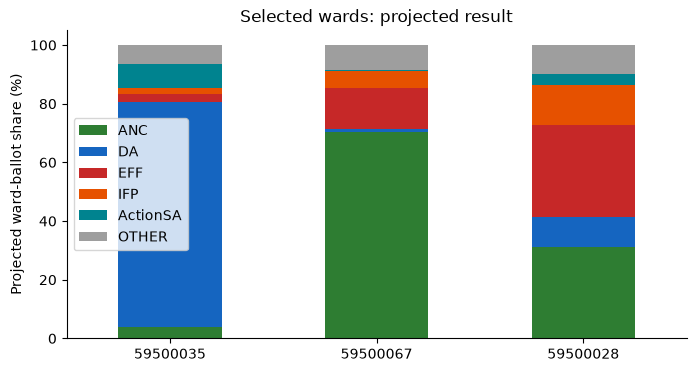

In [26]:
display(R["o2"])
sw = R["shares_by_ward"].loc[R["chosen"]][[c for c in R["wd"]["names"]]]
ax = sw.plot.bar(stacked=True, color=[COL[c] for c in sw.columns], figsize=(8, 4))
ax.set_ylabel("Projected ward-ballot share (%)"); ax.set_title("Selected wards: projected result"); plt.xticks(rotation=0); plt.show()

## Output 3 - Total vote share per party (with 80% range)

,Projected share (%),Low (10th pct),High (90th pct),Projected votes,Seats
ANC,36.5,28.7,43.9,345854.4,82
DA,20.3,16.6,23.8,192672.3,46
EFF,15.4,11.1,20.1,145749.9,34
IFP,9.6,7.1,12.0,90903.5,21
ActionSA,3.6,2.6,4.7,33744.9,8
OTHER,14.6,10.9,18.8,138318.3,33


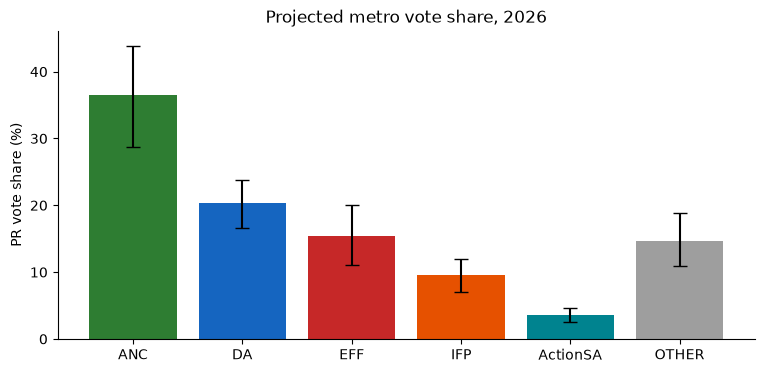

In [27]:
o3 = R["o3"]; display(o3)
fig, ax = plt.subplots(figsize=(9, 4))
err = [o3["Projected share (%)"]-o3["Low (10th pct)"], o3["High (90th pct)"]-o3["Projected share (%)"]]
ax.bar(o3.index, o3["Projected share (%)"], yerr=err, capsize=5, color=[COL[i] for i in o3.index])
ax.set_ylabel("PR vote share (%)"); ax.set_title("Projected metro vote share, 2026"); plt.show()

## Output 4 - Projected voter turnout (number of voters)

Projected voters: 969,358  (50.8% of 1,909,125 registered)
80% range: 872,781 - 1,079,518


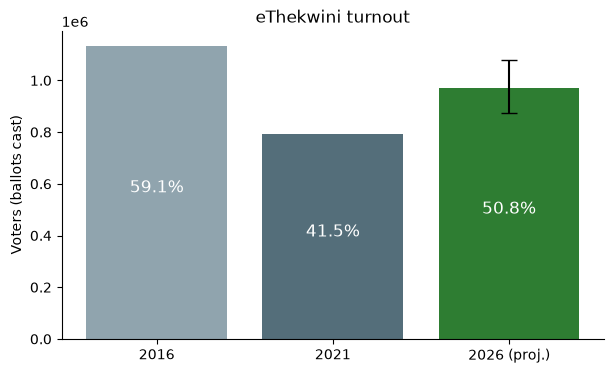

In [28]:
o4 = R["o4"]; h = history(bundles)
print(f"Projected voters: {o4['ballots']:,.0f}  ({o4['turnout']*100:.1f}% of {o4['registered']:,.0f} registered)")
print(f"80% range: {o4['lo']:,.0f} - {o4['hi']:,.0f}")
yrs = ["2016","2021","2026 (proj.)"]; vals = [h["2016"]["ballots"], h["2021"]["ballots"], o4["ballots"]]
fig, ax = plt.subplots(figsize=(7, 4)); b = ax.bar(yrs, vals, color=["#90a4ae","#546e7a","#2e7d32"])
ax.errorbar(2, o4["ballots"], yerr=[[o4["ballots"]-o4["lo"]],[o4["hi"]-o4["ballots"]]], color="k", capsize=6)
for r_, v, t in zip(b, vals, [h["2016"]["turnout"], h["2021"]["turnout"], o4["turnout"]]):
    ax.text(r_.get_x()+r_.get_width()/2, v*0.5, f"{t*100:.1f}%", ha="center", color="w", fontsize=12)
ax.set_ylabel("Voters (ballots cast)"); ax.set_title("eThekwini turnout"); plt.show()

## Sensitivity - how much do the assumptions matter?


,ANC,DA,EFF,IFP,ActionSA,OTHER
persistence=0.0,46.0,24.6,10.2,6.9,2.3,9.9
persistence=0.25,41.4,22.6,12.7,8.2,2.9,12.2
persistence=0.5,36.5,20.3,15.4,9.6,3.6,14.6
persistence=0.75,31.4,17.9,18.2,11.0,4.3,17.1
persistence=1.0,26.4,15.5,21.1,12.4,5.0,19.7


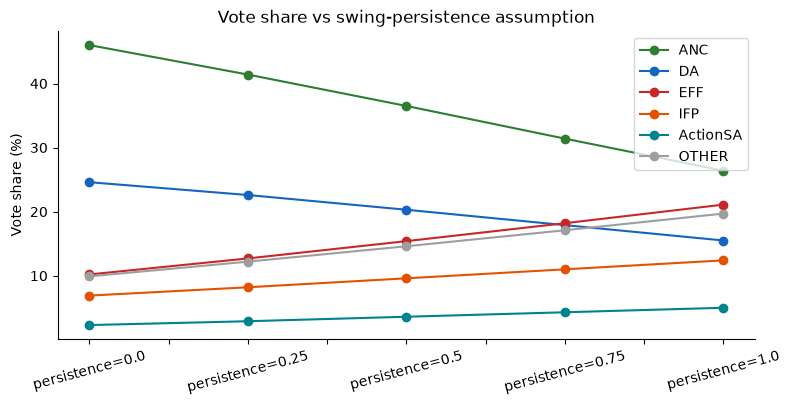

In [29]:
rows = []
for per in [0.0, 0.25, 0.5, 0.75, 1.0]:
    r_ = run_all(bundles, geo, {**params, "persistence": per, "n_sims": 200})
    rows.append(pd.Series(r_["o3"]["Projected share (%)"], name=f"persistence={per}"))
sens = pd.DataFrame(rows); display(sens)
ax = sens.plot(marker="o", color=[COL[c] for c in sens.columns], figsize=(9,4)); ax.set_ylabel("Vote share (%)")
ax.set_title("Vote share vs swing-persistence assumption"); plt.xticks(rotation=15); plt.show()